# Computational Physics Notes
## Orbits and Numerical Integration with Python

**Python Lectures · Week 1** &nbsp;|&nbsp; Study notes by Jamie &nbsp;|&nbsp; Year 2 Physics

---

*These notes cover the Week 1 topics of my computing module: using Python to solve an orbital-mechanics problem, then building numerical integration from scratch. The explanations, examples and code are my own write-up for revision, and the practice questions at the end are for self-testing.*

### What you will learn

1. How to derive **Kepler's third law** and turn it into a Python function.
2. How the equation behaves, and how to read the **limits** of a physical model from a graph.
3. How a **Riemann sum** approximates an integral, with a derivation of its error.
4. Why the **trapezium rule** converges faster.
5. The classic pitfall: **$N$ data points give $N-1$ intervals**.
6. How **random noise** affects an integral, with the statistics derived.

### Contents

| Part | Topic |
|---|---|
| 0 | Setup |
| 1 | Orbits: Kepler's third law in code |
| 2 | Numerical integration: Riemann sums, trapezium rule, data and noise |
| 3 | Practice questions (Q1 worked, Q2 to Q7 to attempt) |
| 4 | Cheat sheet and references |

> **How to use:** run the cells from top to bottom with `Shift + Enter`. Try to predict each output before running a cell.

---
# Part 0 · Setup

In [1]:
import numpy as np                       # fast arrays and maths on whole arrays at once
import matplotlib as mpl                 # plotting (imported for the version number)
import scipy                             # scientific library (physical constants live here)

from matplotlib import pyplot as plt
from scipy import constants

# Consistent, clean plot styling for the whole notebook.
try:
    plt.style.use("seaborn-v0_8-whitegrid")
except OSError:
    pass                                  # fall back to the default style on very old Matplotlib
plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "legend.frameon": True,
})

# Function names can change between versions (np.trapz became np.trapezoid in NumPy 2.0),
# so it is good practice to print versions at the top of a notebook.
print("NumPy", np.__version__, "| Matplotlib", mpl.__version__, "| SciPy", scipy.__version__)

NumPy 2.4.4 | Matplotlib 3.10.8 | SciPy 1.17.1


---
# Part 1 · Orbits: Kepler's third law in code

## 1.1 The physics

For a circular orbit of radius $r$ (measured from the **centre** of the Earth), gravity supplies the centripetal force:

$$F_{\text{grav}} = F_{\text{centripetal}}
\qquad\Longrightarrow\qquad
\frac{GMm}{r^2} = \frac{mv^2}{r}$$

The satellite travels one circumference $2\pi r$ in one period $T$, so

$$v = \frac{2\pi r}{T}\qquad\Rightarrow\qquad v^2=\frac{4\pi^2r^2}{T^2}$$

Substituting and simplifying:

$$\frac{GMm}{r^2} = \frac{m}{r}\cdot\frac{4\pi^2r^2}{T^2} = \frac{4\pi^2 m\,r}{T^2}$$

The satellite mass $m$ cancels, so **the orbit does not depend on the satellite's mass**:

$$\frac{GM}{r^2}=\frac{4\pi^2r}{T^2}
\qquad\Longrightarrow\qquad
\boxed{\,r^3=\frac{GMT^2}{4\pi^2}\,}
\qquad\Longrightarrow\qquad
r=\left(\frac{GMT^2}{4\pi^2}\right)^{1/3}$$

This is **Kepler's third law**: $T^2\propto r^3$. The *altitude* is the height above the surface, so subtract the Earth's radius $R_E$:

$$h=r-R_E$$

> **Radius vs altitude.** The orbital radius is measured from Earth's centre, and altitude from its surface. Mixing these up is the most common mistake in orbit problems.

## 1.2 Turning it into Python

We need $G$ (from `scipy.constants`) plus the mass and mean radius of the Earth (from [Wikipedia](https://en.wikipedia.org/wiki/Earth_mass)). Keep everything in SI units (kg, m, s).

In [2]:
mass_earth = 5.9722e24      # kg
radius_earth = 6371e3       # m   (MEAN radius; the equatorial radius is 6378 km)
sidereal_day = 86400 / (1 + 1 / 365.25)   # s, explained in section 1.3

print("G            =", constants.G, "m^3 kg^-1 s^-2")
print("sidereal day =", round(sidereal_day, 2), "s")

G            = 6.6743e-11 m^3 kg^-1 s^-2
sidereal day = 86164.1 s


In [3]:
def orbit_radius(period):
    '''Orbital radius in metres, from the period in seconds (Kepler's third law).'''
    r_cubed = constants.G * mass_earth * period ** 2 / (4 * np.pi ** 2)   # r^3 = G M T^2 / (4 pi^2)
    return r_cubed ** (1 / 3)        # cube root. The brackets matter: x ** 1/3 would mean (x**1)/3.


def orbit_altitude(period):
    '''Altitude above the surface in metres, from the period in seconds.'''
    return orbit_radius(period) - radius_earth     # altitude = radius from centre - Earth's radius

Writing **two small functions** (radius first, altitude built from it) keeps each one simple. Because every operation inside works element by element on NumPy arrays, both functions also accept a whole array of periods at once. This is called **vectorisation**.

## 1.3 Worked example: a geostationary satellite

A geostationary satellite must stay above the same point on Earth, so it must turn once per **sidereal day** (one rotation relative to the stars), not once per solar day.

Why are they different? In one solar day Earth turns $1+\frac{1}{365.25}$ times relative to the stars, because its orbit around the Sun means it must turn slightly more than $360^\circ$ for the Sun to return to the same place. So

$$T_{\text{sidereal}}=\frac{86400}{1+1/365.25}\approx 86\,164\ \text{s}$$

In [4]:
h_geo = orbit_altitude(sidereal_day)
r_geo = orbit_radius(sidereal_day)

print(f"Geostationary altitude : {h_geo / 1e3:,.1f} km")
print(f"Geostationary radius   : {r_geo / 1e3:,.1f} km (from Earth's centre)")
# The commonly quoted 35 786 km is measured from the EQUATORIAL radius (6378 km).
# Our mean radius is 7 km smaller, so our altitude comes out 7 km larger.

Geostationary altitude : 35,793.2 km
Geostationary radius   : 42,164.2 km (from Earth's centre)


## 1.4 Kepler's third law on a log–log plot

If $r^3\propto T^2$ then $r\propto T^{2/3}$. Taking logs of both sides gives a **straight line**:

$$\ln r=\tfrac{2}{3}\ln T+\text{constant}$$

so on log–log axes the orbit radius against period has slope $2/3$. Plotting it is a good check that the function behaves correctly, and we can mark a few real orbits on it.

Fitted log-log slope = 0.6667  (Kepler predicts 2/3 = 0.6667)


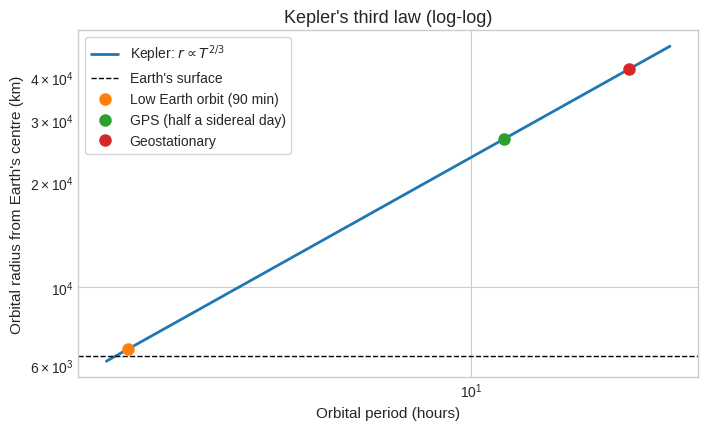

In [5]:
periods = np.logspace(np.log10(80 * 60), np.log10(30 * 3600), 200)   # 80 min to 30 h, log-spaced
radii = orbit_radius(periods)

# Slope check: fit a straight line to (ln T, ln r). Should be 2/3.
slope = np.polyfit(np.log(periods), np.log(radii), 1)[0]
print(f"Fitted log-log slope = {slope:.4f}  (Kepler predicts 2/3 = {2/3:.4f})")

# A few named orbits to mark (period in seconds)
marked = {
    "Low Earth orbit (90 min)": 90 * 60,
    "GPS (half a sidereal day)": sidereal_day / 2,
    "Geostationary": sidereal_day,
}

fig, ax = plt.subplots()
ax.loglog(periods / 3600, radii / 1e3, lw=2, label=r"Kepler: $r \propto T^{2/3}$")
ax.axhline(radius_earth / 1e3, color="k", lw=1, ls="--", label="Earth's surface")

for name, T in marked.items():
    ax.plot(T / 3600, orbit_radius(T) / 1e3, "o", ms=8, label=name)

ax.set(xlabel="Orbital period (hours)", ylabel="Orbital radius from Earth's centre (km)",
       title="Kepler's third law (log-log)")
ax.legend()
plt.show()

## 1.5 The shortest possible orbit

A satellite cannot orbit below the ground, so the lowest orbit skims the surface: $r=R_E$. Solving $R_E^3=GMT^2/4\pi^2$ for $T$:

$$T_{\min}=2\pi\sqrt{\frac{R_E^3}{GM}}$$

In [6]:
t_min = 2 * np.pi * np.sqrt(radius_earth ** 3 / (constants.G * mass_earth))
print(f"T_min = {t_min:.0f} s = {t_min / 60:.2f} min")

# Cross-check with the altitude function: it should return ~0 at T_min.
print(f"orbit_altitude(T_min) = {orbit_altitude(t_min):.6f} m")

# What does a 90-minute period actually correspond to?
print(f"90-minute orbit altitude = {orbit_altitude(90 * 60) / 1e3:.0f} km")

# And a period shorter than T_min gives an impossible (negative) altitude:
print(f"45-minute 'altitude'     = {orbit_altitude(45 * 60) / 1e3:.0f} km  <- inside the Earth, unphysical")

T_min = 5061 s = 84.35 min
orbit_altitude(T_min) = -0.000000 m
90-minute orbit altitude = 282 km
45-minute 'altitude'     = -2180 km  <- inside the Earth, unphysical


> **Key results (Part 1)**
>
> | Quantity | Result |
> |---|---|
> | Geostationary altitude | 35 793 km (35 786 km with the equatorial radius) |
> | Absolute shortest period | 84.3 min (orbit just above the surface, ignoring air resistance) |
> | A 90-minute orbit | about 282 km altitude, a realistic low orbit |
> | Periods below $T_{\min}$ | negative altitude, so physically impossible |

---
# Part 2 · Numerical integration

Many integrals have no neat closed form, and experimental data is just a list of numbers with no formula at all. Numerical integration estimates the area under a curve using only function values.

## 2.1 The Riemann sum

Split $[a,b]$ into $n$ strips of equal width $\Delta x=\dfrac{b-a}{n}$ and use the **left edge** of each strip, $x_i=a+i\,\Delta x$ for $i=0,\dots,n-1$:

$$\int_a^b f(x)\,dx\;\approx\;\sum_{i=0}^{n-1} f(x_i)\,\Delta x$$

Each term is "height $\times$ width", the area of one rectangle.

**Our test integral:** $\displaystyle\int_0^1 e^{x}\,dx=e-1=1.718281828\ldots$

## 2.2 Two implementations

First a **loop** (clear logic, slow), then a **vectorised** version with no loop.

In [7]:
def left_riemann_loop(f, a, b, n):
    '''Left Riemann sum using an explicit loop, so the logic is easy to follow.'''
    width = (b - a) / n                    # Delta x
    total = 0.0                            # running total: an empty "bucket" of area
    for i in range(n):
        x_i = a + i * width                # left edge of rectangle i
        total += f(x_i) * width            # add height * width, i.e. total = total + ...
    return total


def left_riemann(f, a, b, n):
    '''Left Riemann sum with NO loop: evaluate f at all left edges at once, then sum.'''
    width = (b - a) / n
    x_left = a + width * np.arange(n)      # array [a, a+w, a+2w, ..., a+(n-1)w]
    return np.sum(f(x_left)) * width       # factor the width out of the sum


exact = np.e - 1                           # integral of e^x from 0 to 1

print("loop       :", left_riemann_loop(np.exp, 0, 1, 100))
print("vectorised :", left_riemann(np.exp, 0, 1, 100))
print("exact      :", exact)

loop       : 1.7097047383081228
vectorised : 1.7097047383081225
exact      : 1.718281828459045


In [8]:
# How much faster is the vectorised version? (%timeit is a Jupyter "magic" command.)
%timeit left_riemann_loop(np.exp, 0, 1, 100_000)
%timeit left_riemann(np.exp, 0, 1, 100_000)

21.9 ms ± 4.2 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


265 μs ± 3.23 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


## 2.3 Seeing what the rectangles do

For an increasing function the left edge is always the **lowest** point of a strip, so left rectangles sit *under* the curve. The **trapezium rule** instead joins neighbouring points with a straight line, so each strip has the average height $\tfrac{1}{2}(y_i+y_{i+1})$ and hugs the curve far better.

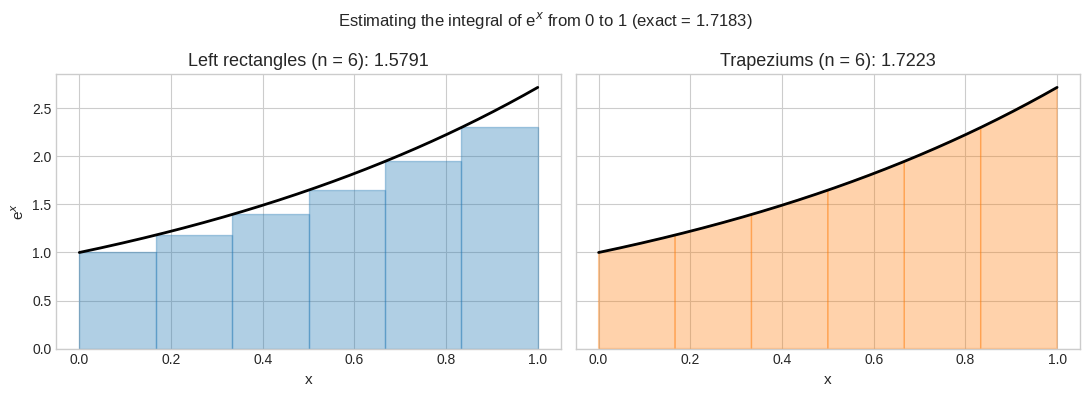

In [9]:
def trapezium(f, a, b, n):
    '''Trapezium rule: n strips, so n + 1 points (this is where N points -> N-1 gaps matters!).'''
    x = np.linspace(a, b, n + 1)
    y = f(x)
    width = (b - a) / n
    # Every interior point is shared by two trapeziums, but the two end points only by one,
    # which is why the ends are halved.
    return width * (np.sum(y) - 0.5 * (y[0] + y[-1]))


n_demo = 6
x_fine = np.linspace(0, 1, 300)
x_nodes = np.linspace(0, 1, n_demo + 1)
dx = 1 / n_demo

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

# Left panel: left rectangles
ax1.plot(x_fine, np.exp(x_fine), "k", lw=2)
ax1.bar(x_nodes[:-1], np.exp(x_nodes[:-1]), width=dx, align="edge", alpha=0.35, edgecolor="C0")
ax1.set(title=f"Left rectangles (n = {n_demo}): "
              f"{left_riemann(np.exp, 0, 1, n_demo):.4f}", xlabel="x", ylabel="e$^x$")

# Right panel: trapeziums
ax2.plot(x_fine, np.exp(x_fine), "k", lw=2)
for i in range(n_demo):
    xs = [x_nodes[i], x_nodes[i], x_nodes[i + 1], x_nodes[i + 1]]
    ys = [0, np.exp(x_nodes[i]), np.exp(x_nodes[i + 1]), 0]
    ax2.fill(xs, ys, alpha=0.35, edgecolor="C1", facecolor="C1")
ax2.set(title=f"Trapeziums (n = {n_demo}): {trapezium(np.exp, 0, 1, n_demo):.4f}", xlabel="x")

fig.suptitle(f"Estimating the integral of e$^x$ from 0 to 1 (exact = {exact:.4f})")
fig.tight_layout()
plt.show()

## 2.4 Why is the left sum off, and by how much?

Within one strip, Taylor's theorem gives $f(x)\approx f(x_i)+f'(x_i)(x-x_i)$. The rectangle keeps only the first term, so the area it misses in strip $i$ is

$$\int_{x_i}^{x_i+\Delta x} f'(x_i)\,(x-x_i)\,dx=f'(x_i)\,\frac{\Delta x^{2}}{2}$$

Adding up all the strips, and recognising $\sum f'(x_i)\Delta x$ as an integral of $f'$:

$$\text{error}\;\approx\;\frac{\Delta x}{2}\sum_i f'(x_i)\,\Delta x\;\approx\;\frac{\Delta x}{2}\int_a^b f'(x)\,dx=\frac{\Delta x}{2}\,\big[f(b)-f(a)\big]$$

For $e^x$ on $[0,1]$ this predicts $\dfrac{\Delta x}{2}(e-1)$. The key point is that the error is proportional to $\Delta x$, so it falls as $1/n$.

For the trapezium rule the same style of argument keeps one more Taylor term and gives

$$\text{error}\;\approx\;-\frac{\Delta x^{2}}{12}\,\big[f'(b)-f'(a)\big]$$

so it scales as $\Delta x^2\propto 1/n^2$, which is much better. For $e^x$ we have $f'=e^x$, so the predicted magnitude is $\dfrac{\Delta x^2}{12}(e-1)$. The sign is negative here because $e^x$ is convex, so trapeziums overshoot.

In [10]:
print(f"{'n':>7} | {'left sum':>10} {'error':>10} {'predicted':>10} | {'trap error':>11} {'predicted':>10}")
print("-" * 70)
for n in [10, 100, 1000]:
    dx = 1 / n
    left_err = exact - left_riemann(np.exp, 0, 1, n)           # positive: the left sum is too small
    left_pred = dx / 2 * (np.e - 1)                            # (dx/2)[f(b) - f(a)]
    trap_err = abs(exact - trapezium(np.exp, 0, 1, n))         # magnitude only
    trap_pred = dx ** 2 / 12 * (np.e - 1)                      # (dx^2/12)[f'(b) - f'(a)]
    print(f"{n:>7} | {left_riemann(np.exp, 0, 1, n):>10.6f} {left_err:>10.2e} {left_pred:>10.2e} "
          f"| {trap_err:>11.2e} {trap_pred:>10.2e}")

      n |   left sum      error  predicted |  trap error  predicted
----------------------------------------------------------------------
     10 |   1.633799   8.45e-02   8.59e-02 |    1.43e-03   1.43e-03
    100 |   1.709705   8.58e-03   8.59e-03 |    1.43e-05   1.43e-05
   1000 |   1.717423   8.59e-04   8.59e-04 |    1.43e-07   1.43e-07


Predictions and measurements agree closely. Now we check the **scaling** on a log–log plot. If $\text{error}\propto n^{-p}$ then $\ln(\text{error})=-p\ln n+\text{const}$, so the slope of the line is $-p$.

Left sum slope  = -0.999   (expected -1)
Trapezium slope = -2.000   (expected -2)


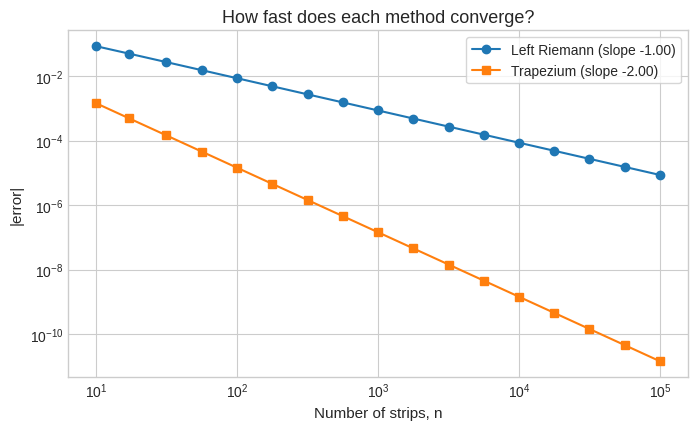

In [11]:
n_values = np.unique(np.logspace(1, 5, 17).astype(int))     # 10 ... 100000, log-spaced
left_errors = np.array([exact - left_riemann(np.exp, 0, 1, n) for n in n_values])
trap_errors = np.array([abs(exact - trapezium(np.exp, 0, 1, n)) for n in n_values])

# Slope of a straight-line fit on log-log axes = minus the power p in error ~ n^-p
p_left = np.polyfit(np.log(n_values), np.log(left_errors), 1)[0]
p_trap = np.polyfit(np.log(n_values), np.log(trap_errors), 1)[0]
print(f"Left sum slope  = {p_left:.3f}   (expected -1)")
print(f"Trapezium slope = {p_trap:.3f}   (expected -2)")

fig, ax = plt.subplots()
ax.loglog(n_values, left_errors, "o-", label=f"Left Riemann (slope {p_left:.2f})")
ax.loglog(n_values, trap_errors, "s-", label=f"Trapezium (slope {p_trap:.2f})")
ax.set(xlabel="Number of strips, n", ylabel="|error|", title="How fast does each method converge?")
ax.legend()
plt.show()

> **Take-away.** To cut the error by a factor of 100, the left sum needs $100\times$ more strips, but the trapezium rule needs only $10\times$ more. A better method beats brute force.

## 2.5 Integrating *measured data*

In an experiment you get arrays, not formulas. Suppose a cart's velocity is sampled every $0.1$ s for 6 s, following $v(t)=20\,e^{-t/2}$ (m/s). The distance travelled is $\int_0^6 v\,dt$, and since we know the formula we can check against the exact answer:

$$\int_0^6 20e^{-t/2}\,dt=40\left(1-e^{-3}\right)=38.0085\ \text{m}$$

**The trap:** `np.linspace(0, 6, 61)` gives **61 points but only 60 intervals**. A sum over 61 heights covers 61 strips, which is one too many.

In [12]:
t = np.linspace(0, 6, 61)           # 61 points  ->  60 gaps
v = 20 * np.exp(-t / 2)             # velocity samples (m/s)
dt = t[1] - t[0]                    # spacing between neighbouring points = 6 / 60 = 0.1 s

exact_distance = 40 * (1 - np.exp(-3))
trapezium_rule = np.trapezoid if hasattr(np, "trapezoid") else np.trapz     # NumPy-version safe

results = {
    "Sum of ALL 61 points  x dt            (61 strips: too many)": np.sum(v) * dt,
    "Sum of ALL 61 points  x (6/61)        (wrong width)":          np.sum(v) * (6 / 61),
    "Left sum, first 60 points  x dt       (correct left sum)":     np.sum(v[:-1]) * dt,
    "Trapezium rule on all points          (best)":                 trapezium_rule(v, t),
}

print(f"Exact distance: {exact_distance:.4f} m\n")
for label, value in results.items():
    print(f"{label}\n    -> {value:.4f} m   (error {value - exact_distance:+.4f})\n")

Exact distance: 38.0085 m

Sum of ALL 61 points  x dt            (61 strips: too many)
    -> 39.0662 m   (error +1.0577)

Sum of ALL 61 points  x (6/61)        (wrong width)
    -> 38.4258 m   (error +0.4173)

Left sum, first 60 points  x dt       (correct left sum)
    -> 38.9666 m   (error +0.9581)

Trapezium rule on all points          (best)
    -> 38.0164 m   (error +0.0079)



For a **decreasing** function the left edge is the *highest* point of each strip, so the left sum now **overestimates** (the opposite of $e^x$). The trapezium rule treats each of the 60 gaps as one strip and is nearly exact.

> **Rule of thumb:** always ask *how many strips do I really have, and what is the width of each?* With $N$ evenly spaced points, there are $N-1$ gaps.

## 2.6 What does noise do to an integral?

Real measurements have random scatter. We add Gaussian (normal) noise with standard deviation $\sigma=0.3$ m/s to each velocity sample. The `Generator` object comes from `np.random.default_rng`, and a **seed** makes the random numbers repeatable (remove the seed for fresh numbers every run).

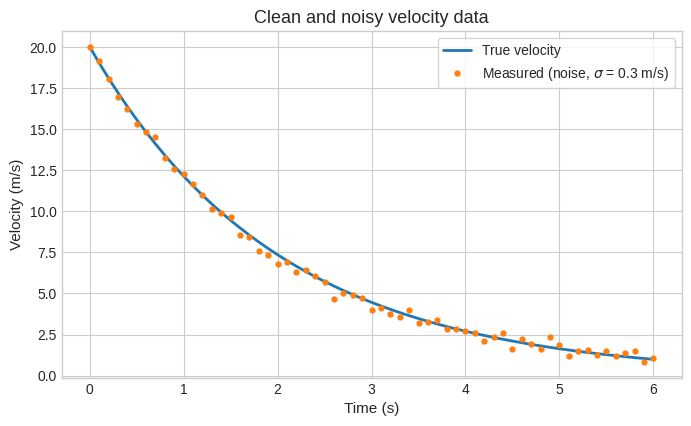

In [13]:
sigma = 0.3                                   # noise standard deviation, m/s
rng = np.random.default_rng(7)                # seed 7 -> reproducible
v_noisy = v + rng.normal(0, sigma, size=v.size)

fig, ax = plt.subplots()
ax.plot(t, v, lw=2, label="True velocity")
ax.plot(t, v_noisy, ".", ms=7, label=r"Measured (noise, $\sigma$ = 0.3 m/s)")
ax.set(xlabel="Time (s)", ylabel="Velocity (m/s)", title="Clean and noisy velocity data")
ax.legend()
plt.show()

### Predicting the effect

With the left sum over $n=60$ strips, the error caused by noise is $\delta=\Delta t\sum_{i=1}^{n}\varepsilon_i$, where $\varepsilon_i$ is the noise on sample $i$.

1. **Mean:** $\langle\varepsilon_i\rangle=0$, so $\langle\delta\rangle=0$. Zero-mean noise does **not bias** the integral.
2. **Variance:** independent random variables add their variances, so
$$\operatorname{Var}(\delta)=\Delta t^{2}\,n\,\sigma^{2}
\quad\Longrightarrow\quad
\sigma_\delta=\Delta t\,\sqrt{n}\,\sigma$$
3. **Numbers:** $\sigma_\delta=0.1\times\sqrt{60}\times0.3=0.232$ m.

Since $\Delta t=T_{\text{total}}/n$ this equals $T_{\text{total}}\,\sigma/\sqrt n$. More samples over the same time reduce the effect of noise as $1/\sqrt n$, and doubling the noise doubles $\sigma_\delta$.

> **If the noise is uniform** on a range of full width $L$ rather than Gaussian, its standard deviation is $\sigma=L/\sqrt{12}$, and the same formula for $\sigma_\delta$ applies.

We test this prediction with 20 000 simulated experiments.

clean left-sum integral : 38.9666 m
simulated mean          : 38.9660 m   (noise adds no bias)
simulated std deviation : 0.2333 m
predicted std deviation : 0.2324 m


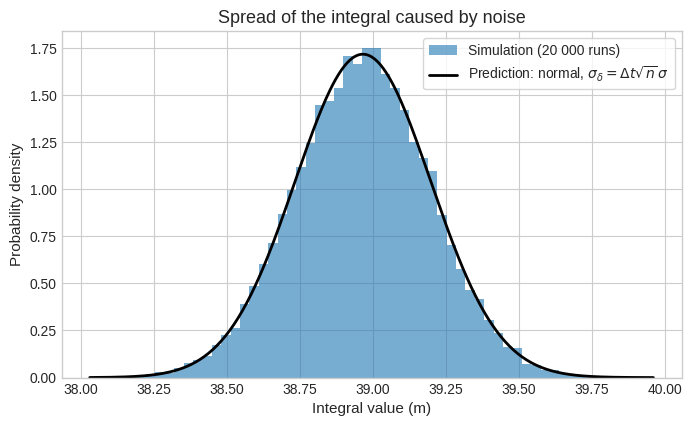

In [14]:
n_strips = v.size - 1                              # 60 strips
rng = np.random.default_rng(7)

n_trials = 20_000
results_noise = np.empty(n_trials)
for k in range(n_trials):
    noisy_v = v + rng.normal(0, sigma, size=v.size)      # a fresh noisy experiment
    results_noise[k] = np.sum(noisy_v[:-1]) * dt         # left sum over the first 60 points

clean_left = np.sum(v[:-1]) * dt
predicted_std = dt * np.sqrt(n_strips) * sigma

print(f"clean left-sum integral : {clean_left:.4f} m")
print(f"simulated mean          : {results_noise.mean():.4f} m   (noise adds no bias)")
print(f"simulated std deviation : {results_noise.std():.4f} m")
print(f"predicted std deviation : {predicted_std:.4f} m")

# Histogram with the predicted normal curve laid on top
fig, ax = plt.subplots()
ax.hist(results_noise, bins=60, density=True, alpha=0.6, label="Simulation (20 000 runs)")
xs = np.linspace(results_noise.min(), results_noise.max(), 400)
pdf = np.exp(-(xs - clean_left) ** 2 / (2 * predicted_std ** 2)) / (predicted_std * np.sqrt(2 * np.pi))
ax.plot(xs, pdf, "k", lw=2, label=r"Prediction: normal, $\sigma_\delta = \Delta t\sqrt{n}\,\sigma$")
ax.set(xlabel="Integral value (m)", ylabel="Probability density",
       title="Spread of the integral caused by noise")
ax.legend()
plt.show()

> **Key results (Part 2)**
>
> | Idea | Result |
> |---|---|
> | Left Riemann sum | error $\approx\frac{\Delta x}{2}[f(b)-f(a)]\propto 1/n$ |
> | Trapezium rule | error $\approx-\frac{\Delta x^2}{12}[f'(b)-f'(a)]\propto 1/n^2$ |
> | $N$ data points | $N-1$ intervals |
> | Zero-mean noise | no bias; scatter $\sigma_\delta=\Delta x\sqrt{n}\,\sigma\propto1/\sqrt n$ at fixed length |

---
# Part 3 · Practice questions

Use $G$ from `scipy.constants`, $M_E=5.9722\times10^{24}$ kg and $R_E=6371$ km. Write functions where sensible, comment your code, and label every graph.

| # | Topic | Status |
|---|---|---|
| Q1 | GPS altitude | worked solution below |
| Q2 | Moon's orbital radius | to attempt |
| Q3 | Period function and plot | to attempt |
| Q4 | Riemann sums and error prediction | to attempt |
| Q5 | Integrating data | to attempt |
| Q6 | Noise | to attempt |
| Q7 | Conceptual | to attempt |

---

**Q1 (orbits).** GPS satellites orbit with a period of half a sidereal day (11 h 58 min 2 s). Derive the altitude by hand from $F_{\text{grav}}=F_{\text{centripetal}}$, then check with your function.

**Q2 (orbits).** The Moon's orbital period is 27.32 days. Treating its mass as negligible compared with Earth's, calculate its orbital radius. Comment on the percentage difference from the accepted 384 400 km and give one physical reason for it.

**Q3 (orbits and plotting).** Write `orbital_period(altitude)` (the inverse of the altitude function). Evaluate it for the ISS at 408 km, then plot period (minutes) against altitude (0 to 2000 km) with labelled axes and a grid. Mark $T_{\min}$ on the graph.

**Q4 (Riemann sums and error).** Without loops, compute $\int_0^2x^2\,dx$ using left Riemann sums for $n=10,100,1000$.
- (a) Find the exact answer.
- (b) Use $\text{error}\approx\frac{\Delta x}{2}[f(b)-f(a)]$ to **predict** each error before running the code.
- (c) Compare, then explain why the sum is below the exact value.

**Q5 (integrating data).** Create `x = np.linspace(0, 5, 51)` and `y = np.exp(-x)`.
- (a) Find the exact integral.
- (b) Compute it with `np.sum(y) * width`, taking care over what the correct width is.
- (c) Compute it with the trapezium rule.
- (d) Explain in two sentences why $N$ points correspond to $N-1$ intervals.

**Q6 (noise).** Add uniform noise on $[-0.2,0.2]$ to $y=e^{-x}$ from Q5.
- (a) Predict the standard deviation of the integral using $\sigma_\delta=\Delta x\sqrt n\,\sigma$ (show your variance derivation).
- (b) Repeat the noisy integration 1000 times, plot a histogram, and compare the mean and spread with your prediction.
- (c) What happens to the spread if you double the number of points over the same interval?

**Q7 (conceptual).**
- (a) Show that the sidereal vs solar day difference is $\approx86400/365.25$ s.
- (b) Why does a sum with $n=10$ do worse than with $n=1000$, and by what factor?
- (c) Name one situation where noise would **bias** an integral rather than just add scatter.

---
## Q1 · Worked solution: altitude of a GPS satellite

**Step 1: equate the forces.** Gravity provides the centripetal force:

$$F_{\text{grav}} = F_{\text{centripetal}}$$

$$\frac{GMm}{r^2} = \frac{mv^2}{r}$$

**Step 2: write the speed using the period.** The satellite travels one circumference $2\pi r$ in one period $T$:

$$v = \frac{2\pi r}{T}$$

**Step 3: substitute and simplify.**

$$\frac{GMm}{r^2} = \frac{m}{r}\cdot\frac{4\pi^2 r^2}{T^2} = \frac{4\pi^2 m\, r}{T^2}$$

The mass $m$ cancels:

$$\frac{GM}{r^2} = \frac{4\pi^2 r}{T^2}$$

**Step 4: make $r$ the subject.** Multiply both sides by $\dfrac{r^2 T^2}{4\pi^2}$:

$$r^3 = \frac{GMT^2}{4\pi^2} \quad\Rightarrow\quad r = \left(\frac{GMT^2}{4\pi^2}\right)^{1/3}$$

**Step 5: convert to altitude.** Subtract Earth's radius:

$$h = r - R_E$$

**Step 6: numbers.** $T = 11\times3600 + 58\times60 + 2 = 43\,082\ \text{s}$, which gives $r\approx26\,562$ km and $h\approx20\,191$ km.

In [2]:
# Q1 (fresh attempt): altitude of a GPS satellite.
# Self-contained: needs nothing from earlier cells.
import numpy as np
from scipy import constants

# --- Constants (SI units) ---
grav_const = constants.G            # m^3 kg^-1 s^-2
earth_mass_kg = 5.9722e24           # kg
earth_radius_m = 6371e3             # m (mean radius)

# --- Given: orbital period of a GPS satellite, 11 h 58 min 2 s, in seconds ---
period_s = 11 * 3600 + 58 * 60 + 2

# --- Kepler's third law, one step per line:  r^3 = G M T^2 / (4 pi^2) ---
gm = grav_const * earth_mass_kg                 # G times M
period_squared = period_s ** 2                  # T^2
r_cubed = gm * period_squared / (4 * np.pi ** 2)
orbit_r_m = r_cubed ** (1 / 3)                  # cube root: brackets around 1/3 are essential

# --- Altitude is measured from the surface, so subtract Earth's radius ---
altitude_m = orbit_r_m - earth_radius_m

print(f"r^3      = {r_cubed:.4e} m^3")
print(f"radius   = {orbit_r_m / 1e3:,.1f} km (from Earth's centre)")
print(f"altitude = {altitude_m / 1e3:,.1f} km (above the surface)")

# --- Independent check: put r back into T = 2 pi sqrt(r^3 / GM).
# We should recover the period we started with. ---
period_check_s = 2 * np.pi * np.sqrt(orbit_r_m ** 3 / gm)
print(f"period recovered from r = {period_check_s:.2f} s   (started with {period_s} s)")

r^3      = 1.8740e+22 m^3
radius   = 26,561.8 km (from Earth's centre)
altitude = 20,190.8 km (above the surface)
period recovered from r = 43082.00 s   (started with 43082 s)


---
## Q2 · My answer

*Hints:* convert days to seconds first. The accepted value is a radius measured from Earth's centre, so compare radius with radius, not altitude.

*Written working (double-click to edit):*

**Q2 (orbits).** The Moon's orbital period is 27.32 days. Treating its mass as negligible compared with Earth's, calculate its orbital radius. Comment on the percentage difference from the accepted 384 400 km and give one physical reason for it

In [ ]:
# same general idea however moons radius and take from the core of the earth

def 

---
## Q3 · My answer

*Hint:* rearrange $r^3=GMT^2/4\pi^2$ for $T$ in terms of $r=R_E+h$. Remember to convert km and minutes at the right moments.

*Written working (double-click to edit):*

In [17]:
# Q3: code here

---
## Q4 · My answer

*Hint:* write the exact answer first, then predict, then run the code.

*Written working (double-click to edit):*

In [18]:
# Q4: code here

---
## Q5 · My answer

*Hint:* count the intervals, not the points.

*Written working (double-click to edit):*

In [19]:
# Q5: code here

---
## Q6 · My answer

*Hint:* the standard deviation of uniform noise of full width $L$ is $L/\sqrt{12}$.

*Written working (double-click to edit):*

In [20]:
# Q6: code here

---
## Q7 · My answer

*Hint:* part (c) is about noise that is not centred on zero, or a non-linear step applied to noisy data.

*Written working (double-click to edit):*

In [21]:
# Q7: code here

---
# Part 4 · Cheat sheet and references

## Formulas

| Topic | Formula |
|---|---|
| Kepler's third law | $r^3=\dfrac{GMT^2}{4\pi^2}$ |
| Altitude | $h=r-R_E$ |
| Shortest period | $T_{\min}=2\pi\sqrt{R_E^3/GM}$ |
| Strip width | $\Delta x=\dfrac{b-a}{n}$ |
| Left Riemann sum | $\sum_{i=0}^{n-1}f(x_i)\Delta x$, error $\approx\dfrac{\Delta x}{2}[f(b)-f(a)]$ |
| Trapezium rule | $\Delta x\left[\tfrac12 y_0+y_1+\dots+y_{n-1}+\tfrac12 y_n\right]$, error $\approx-\dfrac{\Delta x^2}{12}[f'(b)-f'(a)]$ |
| Uniform noise | $\sigma=L/\sqrt{12}$ |
| Noise in an integral | $\sigma_\delta=\Delta x\sqrt{n}\,\sigma$ |

## Python reminders

| Code | Meaning |
|---|---|
| `1e3` | $1\times10^{3}=1000$ |
| `x ** (1/3)` | cube root (**brackets needed**) |
| `np.linspace(a, b, N)` | $N$ points from $a$ to $b$ **including** both ends, so $N-1$ gaps |
| `np.arange(a, b, step)` | points from $a$ up to but **not including** $b$ |
| `return` | hands a value out of a function; without it you get `None` |
| `plt.subplots()` | always creates a brand new figure |
| `%timeit expr` | Jupyter command that times an expression |

## References

- [Kepler's laws of planetary motion](https://en.wikipedia.org/wiki/Kepler%27s_laws_of_planetary_motion)
- [Riemann sum](https://en.wikipedia.org/wiki/Riemann_sum) and [trapezoidal rule](https://en.wikipedia.org/wiki/Trapezoidal_rule)
- [Sidereal time](https://en.wikipedia.org/wiki/Sidereal_time)
- [NumPy documentation](https://numpy.org/doc/stable/) · [Matplotlib documentation](https://matplotlib.org/stable/)
- Earth [mass](https://en.wikipedia.org/wiki/Earth_mass) and [radius](https://en.wikipedia.org/wiki/Earth_radius) values